# 05 - Ensemble Model Training

## 1. Objective

Notebook 04 set two baselines for predicting next week's dengue cases (`cases_next`) on the 2023 validation year. A single Decision Tree did **not** beat persistence.

An **ensemble** combines many models, usually decision trees, so that their individual mistakes partly cancel out. This notebook trains the two main types of tree ensemble and compares them with the baselines:

| Model | Ensemble type | How the trees are combined |
|---|---|---|
| Random Forest | **Bagging** | many independent trees trained in parallel, predictions **averaged** |
| XGBoost | **Boosting** | trees trained **one after another**, each one correcting the errors of the trees before it |

The same 11 features, the same leakage check and the same chronological split as notebook 04 are used. The test set (`test.csv`, 2024-2026) is **not loaded**.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

TRAIN_PATH = Path("../dataset/processed/train.csv")
OUTPUT_PATH = Path("../models/05_selected_model.json")

# the 11 input features created in notebook 03
FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]
TARGET = "cases_next"

VALIDATION_YEAR = 2023
RANDOM_STATE = 42
TREE_MAX_DEPTH = 5  # best Decision Tree setting from notebook 04

# chart colours (the same in notebook 04)
COLORS = {"Persistence": "#898781", "Decision Tree": "#eb6834", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a"}
INK, GRID = "#0b0b0b", "#e4e3df"

## 2. Load the data, remove leaky rows, split by time

These are the same steps as notebook 04, repeated so this notebook runs on its own:
1. Load `train.csv` (target weeks up to 2023 only).
2. **Leakage check:** remove rows whose current week was interpolated (`is_imputed`). Their value was calculated from next week's cases, i.e. from the target. Also remove rows whose target was interpolated (`target_imputed`).
3. **Chronological split:** train on target weeks 2007-2022, validate on 2023.

In [2]:
data = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
assert data["target_date"].max() <= pd.Timestamp("2023-12-31")  # no test weeks
assert data[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES

# leakage check: interpolated weeks
leaky_or_estimated = data["is_imputed"] | data["target_imputed"]
data = data[~leaky_or_estimated].reset_index(drop=True)
print("removed interpolated rows:", leaky_or_estimated.sum())

# chronological split
target_year = data["target_date"].dt.year
train = data[target_year < VALIDATION_YEAR]
valid = data[target_year == VALIDATION_YEAR]
assert train["target_date"].max() < valid["target_date"].min()

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

print("training rows:  ", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("validation rows:", len(valid), "| target weeks", valid["target_date"].min().date(), "to", valid["target_date"].max().date())

removed interpolated rows: 52
training rows:   20332 | target weeks 2007-12-29 to 2022-12-31
validation rows: 1352 | target weeks 2023-01-07 to 2023-12-30


## 3. Baselines from notebook 04

- **Persistence:** next week = this week.
- **Decision Tree** with `max_depth = 5` (the best setting in notebook 04).

**MAE** is the average error in cases, and **RMSE** gives more weight to large misses. Lower is better for both.

In [3]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

results = []          # validation scores, one row per model
predictions = {}      # validation predictions, used for the charts

predictions["Persistence"] = valid["current_week_cases"].to_numpy()
results.append({"model": "Persistence", "settings": "none", **evaluate(y_valid, predictions["Persistence"])})

decision_tree = DecisionTreeRegressor(max_depth=TREE_MAX_DEPTH, random_state=RANDOM_STATE)
decision_tree.fit(X_train, y_train)
predictions["Decision Tree"] = decision_tree.predict(X_valid)
results.append({"model": "Decision Tree", "settings": f"max_depth={TREE_MAX_DEPTH}",
                **evaluate(y_valid, predictions["Decision Tree"])})

pd.DataFrame(results).round(2)

,model,settings,MAE,RMSE
0,Persistence,none,18.17,41.82
1,Decision Tree,max_depth=5,18.96,43.01


## 4. Random Forest (bagging)

**Bagging** = **b**ootstrap **agg**regat**ing**:
1. **Bootstrap:** each tree is trained on a random sample of the training rows, drawn *with replacement*, so every tree sees a slightly different dataset.
2. **Random features:** at each split a tree may only consider a random subset of the features. This makes the trees even more different from each other.
3. **Aggregating:** the forest's prediction is the **average** of all the trees' predictions.

A single deep tree overfits (notebook 04). Averaging many different deep trees cancels much of that noise, which lowers the **variance** of the model.

**Settings compared** (`n_estimators` = number of trees):

| Setting | Meaning |
|---|---|
| default | 100 trees, grown without limit |
| `min_samples_leaf = 10` | every leaf must contain at least 10 training rows, so the trees are smoother |
| `max_depth = 10` | each tree can ask at most 10 questions in a row |

In [4]:
forest_settings = {
    "default (100 trees)": {"n_estimators": 100},
    "200 trees, min_samples_leaf=10": {"n_estimators": 200, "min_samples_leaf": 10},
    "200 trees, max_depth=10": {"n_estimators": 200, "max_depth": 10},
}

forest_rows = []
forest_models = {}
for name, params in forest_settings.items():
    forest = RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    forest.fit(X_train, y_train)
    forest_models[name] = forest

    train_mae = mean_absolute_error(y_train, forest.predict(X_train))
    forest_rows.append({"setting": name, "training MAE": train_mae, **evaluate(y_valid, forest.predict(X_valid))})

forest_results = pd.DataFrame(forest_rows)
forest_results.round(2)

,setting,training MAE,MAE,RMSE
0,default (100 trees),3.80,18.64,43.88
1,"200 trees, min_samples_leaf=10",8.08,18.14,42.32
2,"200 trees, max_depth=10",7.86,18.35,43.42


**What this shows**

- Even the **default forest** (validation MAE 18.64) is far better than a single unlimited tree (28.03 in notebook 04), although each of its trees is also grown without limit. Averaging 100 different trees cancels most of the overfitting. This is the main idea of bagging.
- The training MAE (3.80) is still much lower than the validation MAE, so the default forest still overfits somewhat.
- Requiring **at least 10 rows per leaf** gives the best validation MAE (**18.14**). All three forests beat the best single Decision Tree (18.96).

In [5]:
best_forest_name = forest_results.loc[forest_results["MAE"].idxmin(), "setting"]
best_forest = forest_models[best_forest_name]
print("selected Random Forest setting:", best_forest_name)

predictions["Random Forest"] = best_forest.predict(X_valid)
results.append({"model": "Random Forest", "settings": best_forest_name,
                **evaluate(y_valid, predictions["Random Forest"])})

selected Random Forest setting: 200 trees, min_samples_leaf=10


## 5. XGBoost (boosting)

**Boosting** builds trees **sequentially**:
1. Start with a simple prediction (the average number of cases).
2. Train a small tree to predict the **errors** (residuals) of the current model.
3. Add this tree to the model, scaled down by the **learning rate** (e.g. 0.1 = take 10% of its correction).
4. Repeat for `n_estimators` rounds.

Each new tree focuses on what the model still gets wrong, so boosting mainly reduces **bias**. The trees are usually shallow (`max_depth` 2-6). With too many rounds or too high a learning rate, boosting can also overfit.

XGBoost ("eXtreme Gradient Boosting") is a fast and popular implementation of this idea.

**Settings compared:**

| Setting | `n_estimators` | `max_depth` | `learning_rate` |
|---|---|---|---|
| default | 100 | 6 | 0.3 |
| medium | 200 | 3 | 0.1 |
| slow and shallow | 400 | 2 | 0.05 |

A lower learning rate makes smaller steps, so it needs more rounds.

Unlike a Random Forest (which averages real case counts), boosting adds up corrections and can predict a value **below zero**. Case counts cannot be negative, so XGBoost predictions are clipped at 0 with `np.clip`.

In [6]:
xgb_settings = {
    "default (100 rounds, depth 6, lr 0.3)": {"n_estimators": 100, "max_depth": 6, "learning_rate": 0.3},
    "200 rounds, depth 3, lr 0.1": {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.1},
    "400 rounds, depth 2, lr 0.05": {"n_estimators": 400, "max_depth": 2, "learning_rate": 0.05},
}

xgb_rows = []
xgb_models = {}
for name, params in xgb_settings.items():
    booster = XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    booster.fit(X_train, y_train)
    xgb_models[name] = booster

    train_pred = np.clip(booster.predict(X_train), 0, None)  # no negative case counts
    valid_pred = np.clip(booster.predict(X_valid), 0, None)
    xgb_rows.append({"setting": name, "training MAE": mean_absolute_error(y_train, train_pred),
                     **evaluate(y_valid, valid_pred)})

xgb_results = pd.DataFrame(xgb_rows)
xgb_results.round(2)

,setting,training MAE,MAE,RMSE
0,"default (100 rounds, depth 6, lr 0.3)",5.36,20.40,46.30
1,"200 rounds, depth 3, lr 0.1",8.89,19.21,45.39
2,"400 rounds, depth 2, lr 0.05",9.70,18.10,41.34


**What this shows**

- The **default** XGBoost (deep trees, large learning rate 0.3) overfits the most: validation MAE **20.40**.
- Shallower trees with smaller steps generalise better. The **slow and shallow** setting (400 rounds, depth 2, learning rate 0.05) reaches **18.10**.
- As with the Decision Tree and the Random Forest, **simpler, more careful settings work better** on this data.

In [7]:
best_xgb_name = xgb_results.loc[xgb_results["MAE"].idxmin(), "setting"]
best_xgb = xgb_models[best_xgb_name]
print("selected XGBoost setting:", best_xgb_name)

predictions["XGBoost"] = np.clip(best_xgb.predict(X_valid), 0, None)
results.append({"model": "XGBoost", "settings": best_xgb_name,
                **evaluate(y_valid, predictions["XGBoost"])})

selected XGBoost setting: 400 rounds, depth 2, lr 0.05


**A note on choosing settings.** The settings above were picked using the 2023 validation scores, so these scores are slightly optimistic: we chose the setting that happened to do best on 2023. This is exactly why the test set (2024-2026) is kept separate. It will give the final, unbiased score.

## 6. Model comparison

Validation scores on 2023. The last two columns show the change compared with persistence (negative = better than persistence).

In [8]:
comparison = pd.DataFrame(results).set_index("model")
comparison["MAE vs persistence (%)"] = 100 * (comparison["MAE"] / comparison.loc["Persistence", "MAE"] - 1)
comparison["RMSE vs persistence (%)"] = 100 * (comparison["RMSE"] / comparison.loc["Persistence", "RMSE"] - 1)
comparison.round(2)

,settings,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
model,,,,,
Persistence,none,18.17,41.82,0.00,0.00
Decision Tree,max_depth=5,18.96,43.01,4.37,2.86
Random Forest,"200 trees, min_samples_leaf=10",18.14,42.32,-0.17,1.20
XGBoost,"400 rounds, depth 2, lr 0.05",18.10,41.34,-0.39,-1.13


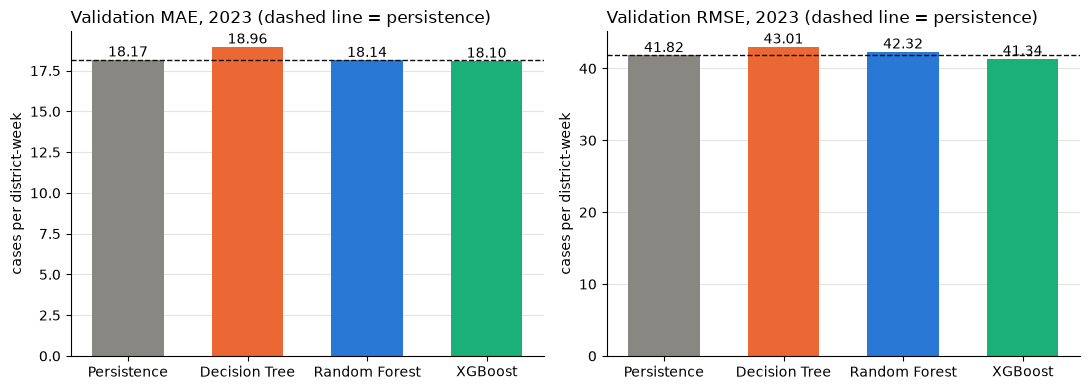

In [9]:
model_names = comparison.index.tolist()
bar_colors = [COLORS[name] for name in model_names]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = comparison[metric].to_numpy()
    ax.bar(model_names, values, color=bar_colors, width=0.6)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(comparison.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Validation {metric}, 2023 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the comparison shows**

- **Both ensembles clearly beat the single Decision Tree** (MAE 18.10-18.14 vs 18.96). Combining many trees, by bagging or by boosting, works better than one tree.
- **Against persistence it is essentially a tie.** XGBoost has slightly lower MAE (-0.4%) and RMSE (-1.1%). The Random Forest has slightly lower MAE (-0.2%) but higher RMSE (+1.2%). Differences of less than 0.1 cases per district-week, measured on a single year, are too small to call a real improvement.
- **Why the ensembles cannot do much better:** all features describe *past* case counts, and next week's count is mostly determined by this week's count (see the feature importance below). The models have learned the persistence pattern plus small adjustments.

## 7. Actual vs predicted: Colombo, 2023

Colombo has the most cases of any district. The chart shows actual weekly cases next to persistence and the two ensemble models.

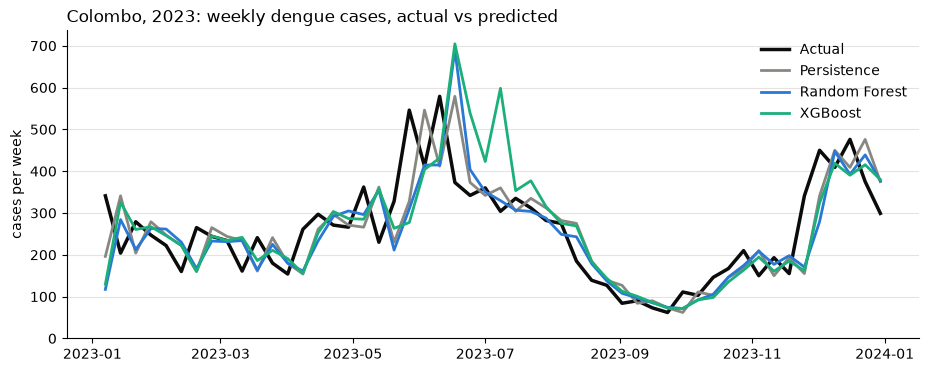

,Persistence,Random Forest,XGBoost
Colombo MAE 2023,65.06,63.02,70.75


In [10]:
colombo_rows = (valid["district"] == "Colombo").to_numpy()
colombo_dates = valid.loc[colombo_rows, "target_date"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(colombo_dates, y_valid[colombo_rows], color=INK, linewidth=2.5, label="Actual")
for name in ["Persistence", "Random Forest", "XGBoost"]:
    ax.plot(colombo_dates, predictions[name][colombo_rows], color=COLORS[name], linewidth=2, label=name)
ax.set_title("Colombo, 2023: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({name: [mean_absolute_error(y_valid[colombo_rows], predictions[name][colombo_rows])]
              for name in ["Persistence", "Random Forest", "XGBoost"]}, index=["Colombo MAE 2023"]).round(2)

All three predictions follow the actual curve about **one week late**: they react to a rise or fall after it has happened. In Colombo, the Random Forest is slightly better than persistence (MAE 63.0 vs 65.1).

XGBoost is worse here (70.8). It **overshoots** after the June peak, predicting about 700 and 600 cases in late June and July when the actual counts had already fallen to around 350-400. So the model with the best overall score is not the best in every district.

## 8. Feature importance

Both ensembles report how much each feature was used to reduce the error. This is a rough guide only: features that are strongly correlated with each other (the lags and moving averages) share the importance between them.

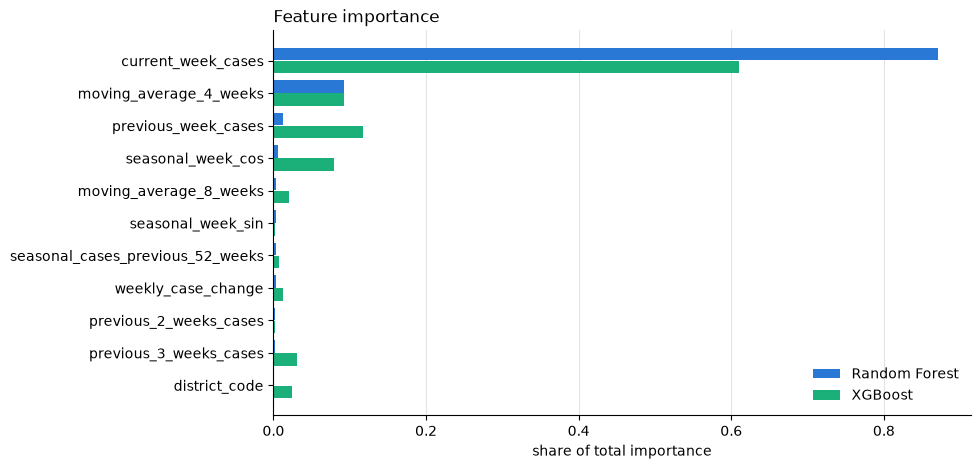

,Random Forest,XGBoost
current_week_cases,0.871,0.610
moving_average_4_weeks,0.092,0.092
previous_week_cases,0.012,0.117
seasonal_week_cos,0.006,0.080
moving_average_8_weeks,0.004,0.020
seasonal_week_sin,0.004,0.003
seasonal_cases_previous_52_weeks,0.003,0.007
weekly_case_change,0.003,0.013
previous_2_weeks_cases,0.002,0.003
previous_3_weeks_cases,0.002,0.031


In [11]:
importance = pd.DataFrame({
    "Random Forest": best_forest.feature_importances_,
    "XGBoost": best_xgb.feature_importances_,
}, index=FEATURES).sort_values("Random Forest")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(importance))
ax.barh(y + 0.2, importance["Random Forest"], height=0.38, color=COLORS["Random Forest"], label="Random Forest")
ax.barh(y - 0.2, importance["XGBoost"], height=0.38, color=COLORS["XGBoost"], label="XGBoost")
ax.set_yticks(y, importance.index)
ax.set_xlabel("share of total importance")
ax.set_title("Feature importance", loc="left")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

importance.sort_values("Random Forest", ascending=False).round(3)

- The **Random Forest** relies almost entirely on `current_week_cases` (0.87), plus the 4-week moving average (0.09). It has essentially learned the persistence rule.
- **XGBoost** spreads its importance a little more: current week 0.61, previous week 0.12, 4-week moving average 0.09 and the seasonal position `seasonal_week_cos` 0.08.
- The 52-week seasonal lag, the longer lags and the district code contribute very little.

## 9. Save the selected model settings

The model with the lowest validation MAE is selected. Its settings are saved to `models/05_selected_model.json`. For the final evaluation, the model is retrained with these settings on all of `train.csv` (2007-2023) and scored once on `test.csv`.

In [12]:
candidates = comparison.drop(index="Persistence")
selected_model = candidates["MAE"].idxmin()

all_params = {
    "Decision Tree": {"max_depth": TREE_MAX_DEPTH},
    "Random Forest": forest_settings[best_forest_name],
    "XGBoost": xgb_settings[best_xgb_name],
}

summary = {
    "selected_model": selected_model,
    "params": all_params[selected_model],
    "random_state": RANDOM_STATE,
    "features": FEATURES,
    "target": TARGET,
    "validation_year": VALIDATION_YEAR,
    "removed_rows": "is_imputed or target_imputed (interpolated weeks)",
    "validation_scores": comparison[["MAE", "RMSE"]].round(3).to_dict(orient="index"),
    "beats_persistence_mae": bool(comparison.loc[selected_model, "MAE"] < comparison.loc["Persistence", "MAE"]),
}
OUTPUT_PATH.parent.mkdir(exist_ok=True)
OUTPUT_PATH.write_text(json.dumps(summary, indent=2))

print("selected model:", selected_model, all_params[selected_model])
print("saved", OUTPUT_PATH)

selected model: XGBoost {'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05}
saved ..\models\05_selected_model.json


## 10. Summary

| Model | Type | Settings | Validation MAE (2023) | Validation RMSE (2023) |
|---|---|---|---|---|
| Persistence | baseline | none | 18.17 | 41.82 |
| Decision Tree | single tree | `max_depth=5` | 18.96 | 43.01 |
| Random Forest | bagging | 200 trees, `min_samples_leaf=10` | 18.14 | 42.32 |
| **XGBoost** | boosting | 400 rounds, `max_depth=2`, `learning_rate=0.05` | **18.10** | **41.34** |

**Selected model: XGBoost** (lowest validation MAE and RMSE), saved to `models/05_selected_model.json`. The Random Forest is practically as good, so both are reasonable choices.

**Key points**
1. **A single tree overfits.** Ensembles fix much of this: averaging many trees (bagging) or adding small, careful corrections (boosting).
2. **Simpler settings generalise better** for all three tree models: larger leaves, shallower trees and a smaller learning rate.
3. **Persistence is hard to beat** for one-week-ahead forecasts. Both ensembles only match it (within 0.5% MAE), because the features mostly repeat what the current week already shows.
4. The leakage check removed interpolated weeks, and the test set was never used, so these scores are fair. They are slightly optimistic only because the settings were chosen on 2023.

**Next steps**
1. **Final evaluation:** retrain the selected model on all of `train.csv` (2007-2023) and score it once on `test.csv` (2024-2026), next to persistence.
2. **Risk classification:** predict `risk_next` (low / medium / high) with the same models as classifiers, evaluated with classification metrics.